# Qwen3.5-0.8B VLM

Aula 4 - Vision-Language Models.

1. Carregar o Qwen3.5-0.8B
2. Olhar encoder visual + language model
3. Inferência (caption) + tokenização
4. VQA com outra imagem
5. (teórico) full fine-tune vs LoRA e VRAM

# 0. Instalando

Qwen3.5 pede `transformers` recente. `accelerate` ajuda no device map. Limitamos pixels da imagem para a aula não explodir em tokens visuais.

In [264]:
#%pip install -q -U "transformers>=5.2.0" "peft>=0.14.0" accelerate torch pillow matplotlib requests

## 1. Imports

In [265]:
from io import BytesIO
from pathlib import Path
import os

import matplotlib.pyplot as plt
import requests
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

HERE = Path.cwd()
if HERE.name != "vlms":
    HERE = Path("exemplos-aula-04/vlms")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.bfloat16 if device.type == "cuda" else torch.float32

print("Device:", device)
print("dtype:", dtype)
print("Pasta:", HERE)

Device: cuda
dtype: torch.bfloat16
Pasta: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-04/vlms


## 2. Carregar o modelo

`Qwen/Qwen3.5-0.8B` é um VLM nativo (~0.8B).  
`min_pixels` / `max_pixels` capam a resolução dinâmica - senão uma foto 12MP vira milhares de tokens visuais.

`HF_HUB_DISABLE_XET=1` evita falha de download no CDN Xet (`CAS Client Error` / file reconstruction).

In [266]:
# desliga o backend Xet do Hub - evita falha CAS no download
os.environ["HF_HUB_DISABLE_XET"] = "1"

MODEL_ID = "Qwen/Qwen3.5-0.8B"

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=512 * 512,
)

model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=dtype)
model = model.to(device).eval()

print(type(model).__name__)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Qwen3_5ForConditionalGeneration


## 3. VLM generativo ≠ CLIP

CLIP: dual encoder → embedding compartilhado → similaridade.  
Qwen VLM: encoder visual + **LLM** que gera texto token a token (caption, VQA, raciocínio sobre a imagem).

In [267]:
root = model.model

print(type(model).__name__)
print(type(root).__name__)
print("visual:", type(root.visual).__name__)
print("language_model:", type(root.language_model).__name__)

Qwen3_5ForConditionalGeneration
Qwen3_5Model
visual: Qwen3_5VisionModel
language_model: Qwen3_5TextModel


## 4. Encoder visual (`visual`)

É o **encoder visual** do Qwen - classe `Qwen3_5VisionModel`.  
Função: transformar a imagem em uma sequência de vetores que o LLM entende (tokens visuais).

In [268]:
visual = root.visual

print(type(visual).__name__)
print("papel: imagem → tokens para o language model")
print(f"params: {sum(p.numel() for p in visual.parameters()) / 1e6:.1f}M")

Qwen3_5VisionModel
papel: imagem → tokens para o language model
params: 100.6M


## 5. Pipeline do encoder

Três etapas: cortar em patches → Transformer → merger (ajusta a dimensão para o LLM).

In [269]:
print("imagem")
print("  ↓  patch_embed   (corta em patches 16×16)")
print("  ↓  blocks        (Transformer, 12 layers)")
print("  ↓  merger        (agrupa patches e projeta p/ dim do LLM)")
print("tokens visuais  →  entram no language_model")

imagem
  ↓  patch_embed   (corta em patches 16×16)
  ↓  blocks        (Transformer, 12 layers)
  ↓  merger        (agrupa patches e projeta p/ dim do LLM)
tokens visuais  →  entram no language_model


## 6. Config do encoder visual

Mesma ideia de um ViT: hidden size, heads, profundidade e tamanho do patch.

In [270]:
vc = visual.config

print(f"hidden_size:         {vc.hidden_size}")
print(f"depth (layers):      {vc.depth}")
print(f"num_heads:           {vc.num_heads}")
print(f"patch_size:          {vc.patch_size}")
print(f"temporal_patch_size: {vc.temporal_patch_size}")
print(f"spatial_merge_size:  {vc.spatial_merge_size}")
print(f"out_hidden_size:     {vc.out_hidden_size}  ← dim do LLM")

hidden_size:         768
depth (layers):      12
num_heads:           12
patch_size:          16
temporal_patch_size: 2
spatial_merge_size:  2
out_hidden_size:     1024  ← dim do LLM


## 7. Submódulos (com params)

Olhada nos filhos de `visual` - sem dumpar o módulo inteiro.

In [271]:
print(f"{'submódulo':20s} {'classe':30s} {'params':>8s}")
print("-" * 62)

for name, child in visual.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"{name:20s} {type(child).__name__:30s} {n / 1e6:7.2f}M")

print()
print("merger: junta patches vizinhos e projeta")
print(f"        {vc.hidden_size} → {vc.out_hidden_size}")

submódulo            classe                           params
--------------------------------------------------------------
patch_embed          Qwen3_5VisionPatchEmbed           1.18M
pos_embed            Embedding                         1.77M
rotary_pos_emb       Qwen3_5VisionRotaryEmbedding      0.00M
blocks               ModuleList                       85.05M
merger               Qwen3_5VisionPatchMerger         12.59M

merger: junta patches vizinhos e projeta
        768 → 1024


## 8. Language model

Decoder (no Qwen3.5: híbrido Gated DeltaNet + attention). É ele quem **gera** a resposta.

In [272]:
lm = root.language_model

print("classe:", type(lm).__name__)

n_lm = sum(p.numel() for p in lm.parameters())
n_vis = sum(p.numel() for p in root.visual.parameters())
n_total = sum(p.numel() for p in model.parameters())

print(f"params language_model: {n_lm / 1e6:.1f}M")
print(f"params visual:         {n_vis / 1e6:.1f}M")
print(f"params total:          {n_total / 1e6:.1f}M")
print(f"fração no LM:          {100 * n_lm / n_total:.1f}%")

classe: Qwen3_5TextModel
params language_model: 752.4M
params visual:         100.6M
params total:          853.0M
fração no LM:          88.2%


## 9. Imagem de exemplo

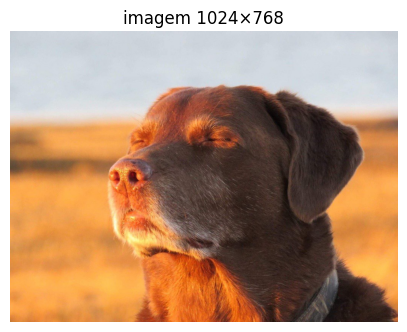

In [273]:
IMAGE_URL = "https://kusart.com/library/meme/dog-accepting-fate-meme/dog-accepting-fate-meme-hero.jpg"

response = requests.get(IMAGE_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
response.raise_for_status()
image = Image.open(BytesIO(response.content)).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title(f"imagem {image.size[0]}×{image.size[1]}")
plt.show()

## 10. Chat multimodal

O processor aplica o **chat template**: imagem + texto viram uma sequência de tokens para o LLM.

In [274]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": "Describe this dog in one short sentence."},
        ],
    }
]

inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
).to(device)

print("chaves:", list(inputs.keys()))
print("seq_len:", inputs["input_ids"].shape[1])

chaves: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values', 'image_grid_thw']
seq_len: 256


## 11. Tokenização da entrada

Mostramos o texto decodificado de cada id. Runs de `<|image_pad|>` ficam só com a **quantidade**.

In [275]:
input_ids = inputs["input_ids"][0].tolist()
tokens = processor.tokenizer.convert_ids_to_tokens(input_ids)

print(f"total de tokens na entrada: {len(tokens)}")
print()
print(f"{'i':>4}  {'id':>8}  peça")
print("-" * 40)

i = 0
while i < len(tokens):
    tok = tokens[i]
    tid = input_ids[i]
    if tok == "<|image_pad|>":
        j = i
        while j < len(tokens) and tokens[j] == "<|image_pad|>":
            j += 1
        print(f"{i:4d}  {tid:8d}  <|image_pad|>  × {j - i}")
        i = j
        continue
    piece = processor.tokenizer.decode([tid])
    print(f"{i:4d}  {tid:8d}  {piece!r}")
    i += 1

total de tokens na entrada: 256

   i        id  peça
----------------------------------------
   0    248045  '<|im_start|>'
   1       846  'user'
   2       198  '\n'
   3    248053  '<|vision_start|>'
   4    248056  <|image_pad|>  × 234
 238    248054  '<|vision_end|>'
 239     72240  'Describe'
 240       411  ' this'
 241      5388  ' dog'
 242       303  ' in'
 243       799  ' one'
 244      2716  ' short'
 245     11316  ' sentence'
 246        13  '.'
 247    248046  '<|im_end|>'
 248       198  '\n'
 249    248045  '<|im_start|>'
 250     74455  'assistant'
 251       198  '\n'
 252    248068  '<think>'
 253       271  '\n\n'
 254    248069  '</think>'
 255       271  '\n\n'


## 12. Inferência (generate)

Geração autoregressiva: o modelo prevê tokens novos depois do prompt.

In [276]:
with torch.no_grad():
    out = model.generate(
        **inputs,
        max_new_tokens=64,
        return_dict_in_generate=True,
        output_scores=True,
    )

generated = out.sequences
trimmed = generated[:, inputs["input_ids"].shape[1]:]
text = processor.batch_decode(trimmed, skip_special_tokens=True)[0]
print(text)

# prob do token escolhido em cada passo (softmax do score)
gen_ids = trimmed[0]
step_probs = []
for step, score in enumerate(out.scores):
    probs = torch.softmax(score[0], dim=-1)
    step_probs.append(float(probs[gen_ids[step]]))

 A chocolate-colored dog with a brown snout and a blue collar is looking up at the sky.



## 13. Sequência de tokens gerados

Lista dos pedaços gerados (BPE): uma palavra pode virar vários tokens.
Mostramos o texto decodificado e a **prob** daquele passo - sem a forma crua do tokenizer (`Ġ...`).

In [277]:
gen_ids = trimmed[0].tolist()

print(f"tokens gerados: {len(gen_ids)}")
print()
print(f"{'i':>4}  {'id':>8}  {'prob':>7}  peça")
print("-" * 40)
for i, (tid, p) in enumerate(zip(gen_ids, step_probs)):
    piece = processor.tokenizer.decode([tid])
    print(f"{i:4d}  {tid:8d}  {p:7.3f}  {piece!r}")

tokens gerados: 23

   i        id     prob  peça
----------------------------------------
   0       357    0.265  ' A'
   1     17395    0.266  ' chocolate'
   2     55787    0.226  '-colored'
   3      5388    0.661  ' dog'
   4       440    0.671  ' with'
   5       264    0.377  ' a'
   6     13477    0.129  ' brown'
   7      3995    0.240  ' sn'
   8       403    0.999  'out'
   9       321    0.457  ' and'
  10       264    0.217  ' a'
  11      6105    0.225  ' blue'
  12     34909    0.952  ' collar'
  13       369    0.338  ' is'
  14      3221    0.322  ' looking'
  15       685    0.233  ' up'
  16       506    0.348  ' at'
  17       279    0.781  ' the'
  18     12515    0.609  ' sky'
  19        13    0.558  '.'
  20    248046    1.000  '<|im_end|>'
  21       198    1.000  '\n'
  22    248044    1.000  '<|endoftext|>'


## 14. VQA

Pergunta nova - o modelo responde em texto, não só ranqueia classes.

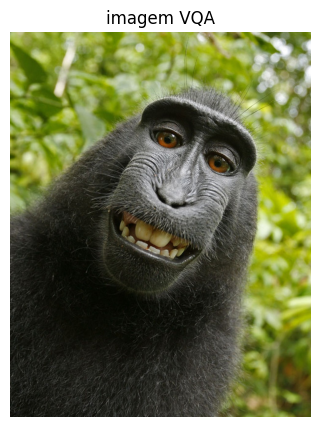

In [278]:
VQA_URL = "https://s2-g1.glbimg.com/MVIpOVDJgHL5JQkPIkh6NbAtkzw=/0x0:620x794/984x0/smart/filters:strip_icc()/s.glbimg.com/jo/g1/f/original/2012/03/06/caters_monkey_snapper_03.jpg"

response_vqa = requests.get(VQA_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
response_vqa.raise_for_status()
image_vqa = Image.open(BytesIO(response_vqa.content)).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image_vqa)
plt.axis("off")
plt.title("imagem VQA")
plt.show()

In [279]:
question = "What animal is this and what is it doing? Answer in one short sentence."
messages_vqa = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image_vqa},
            {"type": "text", "text": question},
        ],
    }
]

inputs_vqa = processor.apply_chat_template(
    messages_vqa,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
).to(device)

with torch.no_grad():
    out_vqa = model.generate(
        **inputs_vqa,
        max_new_tokens=48,
        return_dict_in_generate=True,
        output_scores=True,
    )

answer_ids = out_vqa.sequences[:, inputs_vqa["input_ids"].shape[1]:]
answer = processor.batch_decode(answer_ids, skip_special_tokens=True)[0]
print("Pergunta:", question)
print("Resposta:", answer)

Pergunta: What animal is this and what is it doing? Answer in one short sentence.
Resposta: This is a gorilla, and it is smiling.



In [280]:
print(f"tokens gerados (VQA): {answer_ids.shape[1]}\n")
print(f"{'i':>4}  {'id':>8}  {'prob':>7}  peça")
print("-" * 40)
for i, tid in enumerate(answer_ids[0].tolist()):
    probs = torch.softmax(out_vqa.scores[i][0], dim=-1)
    p = float(probs[tid])
    piece = processor.tokenizer.decode([tid])
    print(f"{i:4d}  {tid:8d}  {p:7.3f}  {piece!r}")

tokens gerados (VQA): 14

   i        id     prob  peça
----------------------------------------
   0      1919    0.237  'This'
   1       369    0.807  ' is'
   2       264    0.844  ' a'
   3     43690    0.396  ' gor'
   4      6045    1.000  'illa'
   5        11    0.351  ','
   6       321    0.503  ' and'
   7       424    0.922  ' it'
   8       369    0.648  ' is'
   9     34869    0.543  ' smiling'
  10        13    0.408  '.'
  11    248046    1.000  '<|im_end|>'
  12       198    1.000  '\n'
  13    248044    1.000  '<|endoftext|>'


## 15. Tokens visuais

`image_grid_thw` = grid (tempo, altura, largura) dos patches.
O merger agrupa `merge_size × merge_size` patches e reduz a sequência.

In [281]:
t, h, w = inputs["image_grid_thw"][0].tolist()
merge = processor.image_processor.merge_size
visual_tokens = (t * h * w) // (merge ** 2)

print("grid (t, h, w):", (t, h, w))
print("merge_size:", merge)
print("visual tokens:", visual_tokens)

grid (t, h, w): (1, 26, 36)
merge_size: 2
visual tokens: 234


## 16. Recap rápido CLIP vs Qwen VLM

| | CLIP | Qwen3.5 VLM |
|---|---|---|
| saída | embeddings + similaridade | texto gerado |
| fusão | tarde (cosine no espaço comum) | cedo (tokens no LLM) |
| uso típico | retrieval / zero-shot class | caption / VQA / chat |
| custo inferência | 1 forward por modalidade | generate token a token |

In [282]:
print("CLIP: bom para ranquear 'a photo of X' sem gerar nada.")
print("Qwen VLM: bom quando a resposta precisa ser uma frase / raciocínio.")

CLIP: bom para ranquear 'a photo of X' sem gerar nada.
Qwen VLM: bom quando a resposta precisa ser uma frase / raciocínio.


## 17. Full fine-tuning (só teoria)

**Full FT** = atualizar **todos** os pesos do modelo (visão + LLM).

O que costuma entrar na conta de VRAM (ordem de grandeza para ~0.8B em bf16):

| pedaço | approx. |
|---|---|
| pesos | ~1.6 GB |
| gradientes | ~1.6 GB |
| Adam (m, v) | ~6+ GB |
| ativações / batch | sobe com `batch` e comprimento da sequência |

Na prática, full FT desse VLM costuma pedir algo na casa de **~12-20 GB** de VRAM, dependendo de batch, resolução da imagem e checkpointing.

A célula abaixo **não treina** - só monta o esqueleto e conta params treináveis.

Obs.: `Trainer` do transformers recente pede `peft` atualizado (`>=0.14`).


In [283]:
"""
%pip install -q -U "peft>=0.14.0"

# transformers recente importa peft por baixo - precisa peft novo
from transformers import TrainingArguments, Trainer

for p in model.parameters():
    p.requires_grad = True

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"params treináveis (full FT): {n_train / 1e6:.1f}M")
print("VRAM típica (ordem de grandeza): ~12-20 GB")

args = TrainingArguments(
    output_dir="ft-qwen-vlm",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=1e-5,
    num_train_epochs=1,
    bf16=True,
)

# esqueleto - sem dataset de verdade não chamamos train()
trainer = Trainer(model=model, args=args)
print(trainer)
"""


'\n%pip install -q -U "peft>=0.14.0"\n\n# transformers recente importa peft por baixo - precisa peft novo\nfrom transformers import TrainingArguments, Trainer\n\nfor p in model.parameters():\n    p.requires_grad = True\n\nn_train = sum(p.numel() for p in model.parameters() if p.requires_grad)\nprint(f"params treináveis (full FT): {n_train / 1e6:.1f}M")\nprint("VRAM típica (ordem de grandeza): ~12-20 GB")\n\nargs = TrainingArguments(\n    output_dir="ft-qwen-vlm",\n    per_device_train_batch_size=1,\n    gradient_accumulation_steps=8,\n    learning_rate=1e-5,\n    num_train_epochs=1,\n    bf16=True,\n)\n\n# esqueleto - sem dataset de verdade não chamamos train()\ntrainer = Trainer(model=model, args=args)\nprint(trainer)\n'

## 18. LoRA (só teoria)

**LoRA** (Low-Rank Adaptation) congela o modelo base e treina só matrizes pequenas (adapters) em algumas camadas (em geral attention: `q/k/v/o`).

Ideia: em vez de mexer em W enorme, aprende `ΔW ≈ B @ A` com rank baixo (`r = 8` ou `16`).

| | Full FT | LoRA |
|---|---|---|
| params treináveis | ~todos (~0.8B) | poucos M |
| VRAM típica (0.8B) | ~12-20 GB | ~4-8 GB |
| lib comum | `transformers` Trainer | `peft` (`LoraConfig`) |

A célula abaixo **não treina** - só mostra o esqueleto com `peft`.

In [284]:
%pip install -q -U "peft>=0.14.0"

from peft import LoraConfig, get_peft_model

for p in model.parameters():
    p.requires_grad = False

lora = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)

model_lora = get_peft_model(model, lora)
model_lora.print_trainable_parameters()
print("VRAM típica (ordem de grandeza): ~4-8 GB")

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
trainable params: 540,672 || all params: 853,526,592 || trainable%: 0.06334565379305722
VRAM típica (ordem de grandeza): ~4-8 GB


## 19. Liberar VRAM

Apaga o modelo da memória e chama `empty_cache` - útil antes de rodar outro notebook na mesma GPU.

In [285]:
import gc

for name in ["model", "model_lora", "trainer", "processor", "inputs", "inputs_vqa", "root", "visual", "lm"]:
    globals().pop(name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM livre: {free / 1e9:.2f} / {total / 1e9:.2f} GB")
else:
    print("CPU only")

VRAM livre: 5.25 / 6.05 GB
